# Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Helper Functions

In [ ]:
def pretty_print(labels, answers, separator):
    for label, answer in zip(labels, answers):
        print(f"{label}{separator}{answer}\n")

# Part 1: Linear Algebra

## Question 1

Given matrices: $$A = \begin{bmatrix}3&4 \\ 2&1\end{bmatrix}, \quad B = \begin{bmatrix}1&2 \\ 0&-1\end{bmatrix}$$ Compute: $$AB, \quad BA, \quad (A+B)^T, \quad \mathrm{trace}(A), \quad \mathrm{trace}(AB)$$

In [ ]:
def matrix_operations(A=None, B=None):
    """Return AB, BA, (A+B).T, A@B.T, trace(A), trace(AB).

    Defaults: A=[[3,4],[2,1]], B=[[1,2],[0,-1]]. Other inputs are square
    real matrices of matching size. Return a tuple in the specified order.
    """
    A = np.array(A) if A is not None else np.array([[3,4],[2,1]])
    B = np.array(B) if B is not None else np.array([[1,2],[0,-1]])
    return A@B, B@A, (A+B).T, A@B.T, np.trace(A), np.trace(A@B)

In [ ]:
matrices = matrix_operations()
labels = ["AB", "BA", "(A+B)^T", "(AB)^T", "trace(A)", "trace(AB)"]
pretty_print(labels, matrices, " = ")

AB = [[3 2]
 [2 3]]

BA = [[ 7  6]
 [-2 -1]]

(A+B)^T = [[4 2]
 [6 0]]

(AB)^T = [[11 -4]
 [ 4 -1]]

trace(A) = 4

trace(AB) = 6



## Question 2

In [ ]:
def eigensystem(M=None):
    """Return (values, vectors) for real symmetric M (default [[2,-1],[-1,2]]).

    Vectors are columns paired with values; order, sign, and nonzero scale
    are free. Vectors must span each eigenspace, including repeated roots.
    """
    M = np.array(M) if M is not None else np.array([[2,-1],[-1,2]])
    eigenvalues, eigenvectors = np.linalg.eig(M)
    return eigenvalues.real, eigenvectors.real # so that you don't get unnecessary imaginary components

In [ ]:
labels = ["Eigenvalues", "Eigenvectors"]
answers = eigensystem()

for i in range(len(answers[0])):
    print(f"lambda_{i+1} = {answers[0][i]}\n"
          f"v_{i+1} = {answers[1][:, i]}\n")

lambda_0 = 3.0
v_0 = [ 0.70710678 -0.70710678]

lambda_1 = 1.0
v_1 = [0.70710678 0.70710678]



## Question 4

In [ ]:
def matrix_inverse(C=None):
    """Return inverse of nonsingular square C; default C=[[4,7],[2,6]]."""
    C = np.array(C) if C is not None else np.array([[4, 7], [2, 6]])
    return np.linalg.inv(C)

In [ ]:
print(f"C^-1 = {matrix_inverse()}")

C^-1 = [[ 0.6 -0.7]
 [-0.2  0.4]]


# Part 3: Principal Component Analysis

## Question 2

In [ ]:
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    """Return reproducible Gaussian samples (n_samples,2) using NumPy and seed.

    Defaults: mean=[2,-1], covariance=[[3,1.2],[1.2,1]]. Custom mean has shape
    (2,), covariance (2,2) is positive definite. Do not mutate input arrays.
    """
    np.random.seed(seed)
    mean = mean if mean is not None else np.array([2, -1])
    covariance = covariance if covariance is not None else np.array([[3, 1.2], [1.2, 1]])
    return np.random.multivariate_normal(mean, covariance, n_samples)

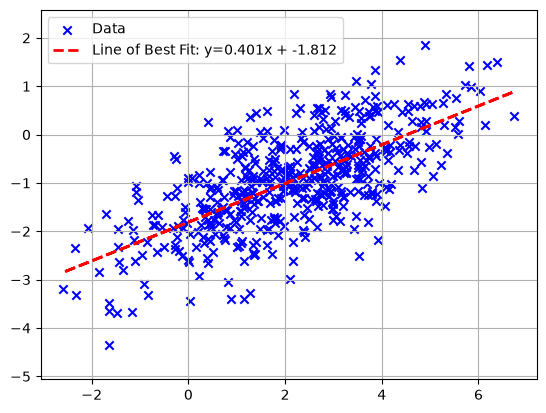

In [ ]:
x, y = generate_data().T
plt.scatter(x, y, color='green', label="Data")

m, b = np.polyfit(x, y, deg=1)
plt.plot(x, m*x + b, color='red', linestyle='--', linewidth=2, label=f"Line of Best Fit: y={m:.3f}x + {b:.3f}")

plt.axis("equal")  # Set equal aspect ratio

plt.legend()
plt.grid(True)
plt.show()

The correlation structure is roughly linear with the line of best fit described above.

## Question 3

In [ ]:
def pca(X):
    """Fit NumPy PCA without mutating finite X of shape (n,2), n>=2.

    Return dict: mean (2,), centered (n,2), covariance (2,2), eigenvalues (2,),
    components (2,2), scores (n,2). Use covariance divisor n-1, descending
    eigenvalues, orthonormal eigenvectors as columns, scores=centered@components.
    Signs/tied-eigenspace bases are free. Include rank-deficient and tied cases.
    NumPy eigh/SVD are allowed; fitted library PCA is not.
    """
    # Center the dataset (subtract the mean)
    mean = np.mean(X, axis=0)
    centered = X - mean

    # Compute the covariance matrix
    covariance = np.cov(centered.T)

    # Compute the eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # Sort the eigenvalues and eigenvectors in descending order
    idx = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]

    # Compute the principal components (scores)
    scores = centered @ eigenvectors

    return {
        "mean": mean,
        "centered": centered,
        "covariance": covariance,
        "eigenvalues": eigenvalues,
        "components": eigenvectors,
        "scores": scores
    }

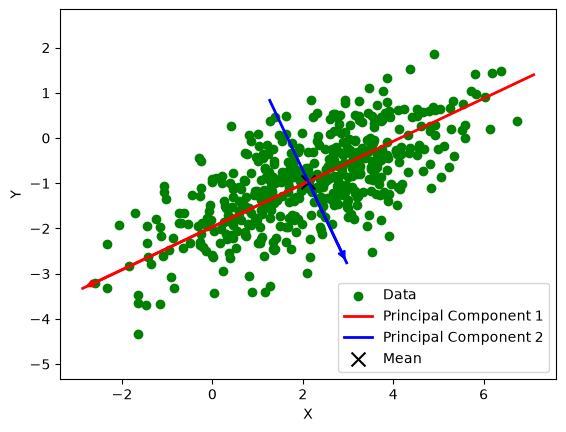

In [ ]:
# Plot principal subspace (the line that maximizes variance) for data
data = np.column_stack((x, y)) # column stack so that each row is a data point
res = pca(data)

mean = res['mean'] # mean of the data
components = res['components'] # principal components
eigenvalues = res['eigenvalues'] # eigenvalues of the principal components

fig, ax = plt.subplots()

ax.scatter(x, y, color='green', label='Data')

colors = ['red', 'blue'] # colors for the principal component lines

for i in range(2):
    direction = res['components'][:, i] # i-th principal component
    length = 3*np.sqrt(res['eigenvalues'][i]) # 3 standard deviations
    start = mean - length * direction
    end = mean + length * direction
    ax.plot(
        [start[0], end[0]], 
        [start[1], end[1]], 
        color=colors[i], 
        linewidth=2, 
        label=f'Principal Component {i+1}'
    )

    ax.annotate(
        "",
        xy=end,
        xytext=mean,
        arrowprops=dict(arrowstyle='->', color=colors[i], linewidth=2)
    )

ax.scatter(mean[0], mean[1], color='black', marker='x', s=100, label='Mean')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.axis('equal')
ax.legend()
plt.show()

## Question 4

In [ ]:
def explained_variance(eigenvalues):
    """Return same-shape fractions for nonnegative eigenvalues with positive sum."""
    total_variance = np.sum(eigenvalues)
    if total_variance == 0:
        return np.zeros_like(eigenvalues)
    return eigenvalues / total_variance

In [ ]:
# Compute portion of variance explained by each principal component
print(explained_variance(eigenvalues))


[0.88520195 0.11479805]
